In [32]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import math
from sklearn.ensemble import HistGradientBoostingRegressor

In [6]:
df=pd.read_csv("salesdaily.csv")
df.head()

,datum,M01AB,M01AE,N02BA,N02BE,N05B,N05C,R03,R06,Year,Month,Hour,Weekday Name
0,01-02-2014,0.0,3.67,3.4,32.40,7.0,0.0,0.0,2.0,2014,1,248,Thursday
1,01-03-2014,8.0,4.00,4.4,50.60,16.0,0.0,20.0,4.0,2014,1,276,Friday
2,01-04-2014,2.0,1.00,6.5,61.85,10.0,0.0,9.0,1.0,2014,1,276,Saturday
3,01-05-2014,4.0,3.00,7.0,41.10,8.0,0.0,3.0,0.0,2014,1,276,Sunday
4,01-06-2014,5.0,1.00,4.5,21.70,16.0,2.0,6.0,2.0,2014,1,276,Monday


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2106 entries, 0 to 2105
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   datum         2106 non-null   str    
 1   M01AB         2106 non-null   float64
 2   M01AE         2106 non-null   float64
 3   N02BA         2106 non-null   float64
 4   N02BE         2106 non-null   float64
 5   N05B          2106 non-null   float64
 6   N05C          2106 non-null   float64
 7   R03           2106 non-null   float64
 8   R06           2106 non-null   float64
 9   Year          2106 non-null   int64  
 10  Month         2106 non-null   int64  
 11  Hour          2106 non-null   int64  
 12  Weekday Name  2106 non-null   str    
dtypes: float64(8), int64(3), str(2)
memory usage: 214.0 KB


In [8]:
print(df["datum"].head(10))
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate dates:", df["datum"].duplicated().sum())

0    01-02-2014
1    01-03-2014
2    01-04-2014
3    01-05-2014
4    01-06-2014
5    01-07-2014
6    01-08-2014
7    01-09-2014
8    01-10-2014
9    01-11-2014
Name: datum, dtype: str
Duplicate rows: 0
Duplicate dates: 0


In [9]:
print(df["datum"].head(20).to_string(index=False))

01-02-2014
01-03-2014
01-04-2014
01-05-2014
01-06-2014
01-07-2014
01-08-2014
01-09-2014
01-10-2014
01-11-2014
01-12-2014
 1/13/2014
 1/14/2014
 1/15/2014
 1/16/2014
 1/17/2014
 1/18/2014
 1/19/2014
 1/20/2014
 1/21/2014


In [10]:
# Convert mixed date formats into proper dates
df["datum"] = pd.to_datetime(
    df["datum"].str.strip(),
    format="mixed",
    dayfirst=False,
    errors="coerce"
)

print(df["datum"].head())
print("Invalid dates:", df["datum"].isna().sum())

# Verify against the existing year and month columns
print("Year mismatches:", (df["datum"].dt.year != df["Year"]).sum())
print("Month mismatches:", (df["datum"].dt.month != df["Month"]).sum())

0   2014-01-02
1   2014-01-03
2   2014-01-04
3   2014-01-05
4   2014-01-06
Name: datum, dtype: datetime64[us]
Invalid dates: 0
Year mismatches: 0
Month mismatches: 0


In [11]:
df = df.sort_values("datum").reset_index(drop=True)

# Missing calendar dates
all_dates = pd.date_range(df["datum"].min(), df["datum"].max())
missing_dates = all_dates.difference(df["datum"])

print("Date range:", df["datum"].min(), "to", df["datum"].max())
print("Missing dates:", len(missing_dates))
print(missing_dates)

# Negative sales in each medicine category
medicine_cols = [
    "M01AB", "M01AE", "N02BA", "N02BE",
    "N05B", "N05C", "R03", "R06"
]

print("\nNegative values:")
print((df[medicine_cols] < 0).sum())

print("\nDuplicate dates after conversion:",
      df["datum"].duplicated().sum())


Date range: 2014-01-02 00:00:00 to 2019-10-08 00:00:00
Missing dates: 0
DatetimeIndex([], dtype='datetime64[us]', freq='D')

Negative values:
M01AB    0
M01AE    0
N02BA    0
N02BE    0
N05B     0
N05C     0
R03      0
R06      0
dtype: int64

Duplicate dates after conversion: 0


In [12]:
# Days when every medicine category recorded zero sales
all_zero = df[medicine_cols].eq(0).all(axis=1)

print("All-zero days:", all_zero.sum())

display(
    df.loc[all_zero, ["datum"] + medicine_cols]
)


All-zero days: 26


,datum,M01AB,M01AE,N02BA,N02BE,N05B,N05C,R03,R06
5,2014-01-07,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
108,2014-04-20,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
119,2014-05-01,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
351,2014-12-19,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
364,2015-01-01,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
370,2015-01-07,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
465,2015-04-12,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
716,2015-12-19,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
729,2016-01-01,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
735,2016-01-07,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [13]:
df["all_zero_sales"] = df[medicine_cols].eq(0).all(axis=1)

In [14]:
display(df[medicine_cols].describe())

,M01AB,M01AE,N02BA,N02BE,N05B,N05C,R03,R06
count,2106.000000,2106.000000,2106.000000,2106.000000,2106.000000,2106.000000,2106.000000,2106.000000
mean,5.033683,3.895830,3.880441,29.917095,8.853627,0.593522,5.512262,2.900198
std,2.737579,2.133337,2.384010,15.590966,5.605605,1.092988,6.428736,2.415816
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,3.000000,2.340000,2.000000,19.000000,5.000000,0.000000,1.000000,1.000000
50%,4.990000,3.670000,3.500000,26.900000,8.000000,0.000000,4.000000,2.000000
75%,6.670000,5.138000,5.200000,38.300000,12.000000,1.000000,8.000000,4.000000
max,17.340000,14.463000,16.000000,161.000000,54.833333,9.000000,45.000000,15.000000


In [15]:
display(
    df.nlargest(10, "N02BE")[["datum"] + medicine_cols]
)

,datum,M01AB,M01AE,N02BA,N02BE,N05B,N05C,R03,R06
1093,2016-12-30,5.66,8.990,7.30,161.00,13.0,0.0,3.0,0.0
1094,2016-12-31,8.33,7.759,7.45,108.70,7.0,0.0,12.0,0.0
1851,2019-01-27,10.52,11.745,2.00,100.10,12.0,1.0,6.0,2.0
1850,2019-01-26,7.00,8.459,2.40,97.80,11.0,1.0,13.0,1.0
1844,2019-01-20,11.67,14.463,2.10,93.05,6.0,0.0,34.0,1.0
1018,2016-10-16,8.33,5.122,10.00,89.30,3.0,0.0,6.0,5.0
1011,2016-10-09,6.68,5.020,5.50,88.40,2.0,0.0,9.0,1.0
737,2016-01-09,7.33,2.660,5.00,88.30,9.0,0.0,3.0,3.0
766,2016-02-07,3.66,6.056,4.50,88.20,2.0,0.0,13.0,1.0
723,2015-12-26,4.67,1.660,5.00,87.20,15.0,3.0,0.0,4.3


In [16]:
display(
    df.loc[
        df["datum"].between("2016-12-25", "2017-01-10"),
        ["datum"] + medicine_cols
    ]
)

,datum,M01AB,M01AE,N02BA,N02BE,N05B,N05C,R03,R06
1088,2016-12-25,2.330000,7.627000,5.700000,79.800000,0.000000,0.000000,9.000000,1.000000
1089,2016-12-26,10.330000,4.660000,2.000000,58.924000,6.000000,0.000000,2.000000,2.000000
1090,2016-12-27,6.000000,5.000000,0.416667,54.200000,8.000000,2.000000,13.000000,0.000000
1091,2016-12-28,4.340000,6.330000,6.450000,57.200000,7.000000,0.000000,13.000000,0.000000
1092,2016-12-29,11.000000,6.010000,6.350000,81.200000,4.000000,3.000000,6.000000,2.000000
1093,2016-12-30,5.660000,8.990000,7.300000,161.000000,13.000000,0.000000,3.000000,0.000000
1094,2016-12-31,8.330000,7.759000,7.450000,108.700000,7.000000,0.000000,12.000000,0.000000
1095,2017-01-01,3.543750,3.956250,1.562500,25.675000,8.750000,1.875000,6.250000,0.625000
1096,2017-01-02,0.212500,0.637500,0.625000,32.000000,0.000000,0.625000,3.125000,3.125000
1097,2017-01-03,6.250000,5.831250,4.625000,66.812500,8.750000,0.000000,7.031250,1.875000


In [17]:
calculated_weekday = df["datum"].dt.day_name()

weekday_mismatch = (
    calculated_weekday != df["Weekday Name"].str.strip()
)

print("Weekday mismatches:", weekday_mismatch.sum())

display(
    df.loc[weekday_mismatch, ["datum", "Weekday Name"]]
)

Weekday mismatches: 0


,datum,Weekday Name


In [18]:
df = df.rename(columns={
    "datum": "date",
    "Weekday Name": "weekday"
})

print("Unique Hour values:", df["Hour"].nunique())
print(df["Hour"].value_counts().head(10))

Unique Hour values: 3
Hour
276    2104
248       1
190       1
Name: count, dtype: int64


In [19]:
df_clean = df.drop(columns=["Hour"]).copy()

df_clean.head()

,date,M01AB,M01AE,N02BA,N02BE,N05B,N05C,R03,R06,Year,Month,weekday,all_zero_sales
0,2014-01-02,0.0,3.67,3.4,32.40,7.0,0.0,0.0,2.0,2014,1,Thursday,False
1,2014-01-03,8.0,4.00,4.4,50.60,16.0,0.0,20.0,4.0,2014,1,Friday,False
2,2014-01-04,2.0,1.00,6.5,61.85,10.0,0.0,9.0,1.0,2014,1,Saturday,False
3,2014-01-05,4.0,3.00,7.0,41.10,8.0,0.0,3.0,0.0,2014,1,Sunday,False
4,2014-01-06,5.0,1.00,4.5,21.70,16.0,2.0,6.0,2.0,2014,1,Monday,False


In [21]:
df_clean.to_csv("salesdaily_cleaned.csv", index=False)
print("saved",df_clean.shape)

saved (2106, 13)


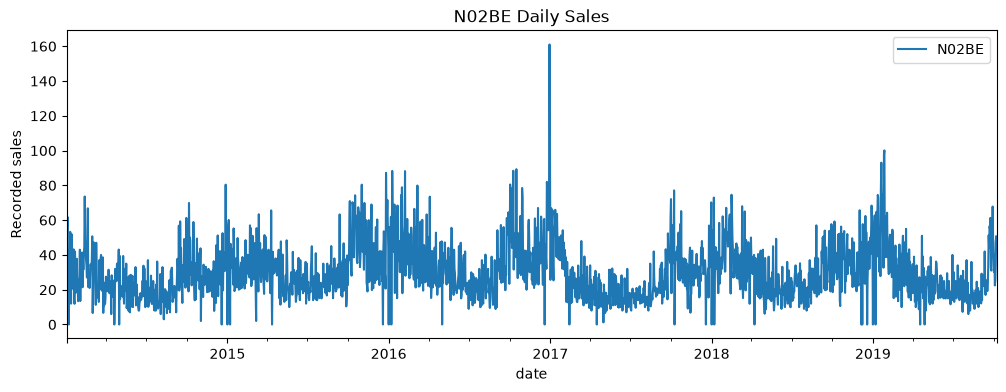

In [22]:
df_clean.plot(x="date", y="N02BE", figsize=(12, 4))
plt.ylabel("Recorded sales")
plt.title("N02BE Daily Sales")
plt.show()

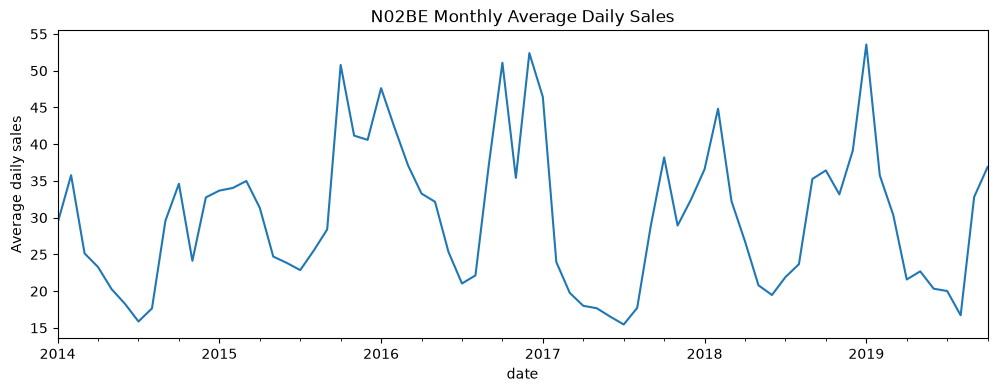

In [23]:
monthly = df_clean.set_index("date")["N02BE"].resample("MS").mean()

monthly.plot(figsize=(12, 4), title="N02BE Monthly Average Daily Sales")
plt.ylabel("Average daily sales")
plt.show()

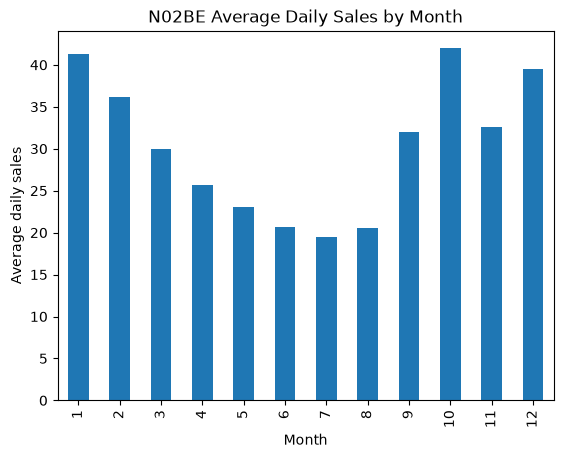

In [24]:
df_clean.groupby("Month")["N02BE"].mean().plot(
    kind="bar", title="N02BE Average Daily Sales by Month"
)
plt.ylabel("Average daily sales")
plt.show()

In [36]:
import pandas as pd
ev = pd.read_csv("stockout_events.csv", parse_dates=["start_date", "end_date"])
sil = ev[(ev.location_id == "DIST_SIL") &
         (ev.start_date >= "2019-06-01") & (ev.start_date <= "2019-09-30")]
print(sil.sort_values("unmet_qty", ascending=False).head(10).to_string(index=False))

sku_id location_id start_date   end_date  days  unmet_qty
 N02BE    DIST_SIL 2019-09-23 2019-09-26     4         38
 N02BE    DIST_SIL 2019-09-08 2019-09-12     5         37
 N02BE    DIST_SIL 2019-09-30 2019-10-02     3         26
 N02BE    DIST_SIL 2019-07-12 2019-07-14     3         15
 N02BE    DIST_SIL 2019-09-19 2019-09-20     2         15
   R03    DIST_SIL 2019-08-07 2019-08-08     2          8
   R06    DIST_SIL 2019-06-17 2019-06-20     4          8
   R03    DIST_SIL 2019-08-11 2019-08-13     3          7
   R03    DIST_SIL 2019-07-30 2019-07-31     2          7
 M01AB    DIST_SIL 2019-08-02 2019-08-05     4          6


In [1]:
print(rec[(rec.location_id == "DIST_SIL") & (rec.sku_id == "N02BE")].to_string(index=False))
print(rec.status.value_counts())

NameError: name 'rec' is not defined